# Лабораторна робота №2 — Розвідувальний аналіз даних (EDA)
## Тема: Розвідувальний аналіз даних для задач регресії.

## Обраний датасет: used_cars.csv — дані про вживані автомобілі.

## 1. Підготовка проєкту та первинне ознайомлення

#### 1.1. Що містить обраний датасет

#### У датасеті є такі змінні:
| Змінна       | Опис                                      |
|--------------|-------------------------------------------|
| brand        | Марка автомобіля                          |
| model        | Модель автомобіля                         |
| model_year   | Рік випуску автомобіля                    |
| milage       | Пробіг автомобіля                         |
| fuel_type    | Тип пального                              |
| engine       | Характеристики двигуна                    |
| transmission | Тип коробки передач                       |
| ext_col      | Колір кузова автомобіля                   |
| int_col      | Колір салону автомобіля                   |
| accident     | Інформація про наявність ДТП              |
| clean_title  | Статус документів автомобіля              |
| price        | Ціна автомобіля                           |

#### Цільова змінна — **price**.



## 1.2. Постановка задачі

## Мета дослідження

### Дослідити характеристики вживаних автомобілів та визначити, які фактори пов'язані з їхньою ціною.

### Одиниця спостереження

### Один запис про автомобіль у наборі даних.

#### Дослідницькі запитання
#### 1. Як розподіляються ціни вживаних автомобілів?
#### 2. Як рік випуску пов'язаний із ціною автомобіля?
#### 3. Чи існує зв'язок між пробігом і ціною?
#### 4. Як відрізняються ціни залежно від марки та типу пального?
#### 5. Як пов'язані з ціною історія ДТП, рік випуску та пробіг при спільному аналізі?

## 1.3. Створюємо структуру проєкту в Positron

In [1]:

#dirs <- c(
#  "data/raw",
#  "data/processed",
#  "notebooks",
#  "outputs/tables",
#  "outputs/figures",
#  "outputs/metadata",
#  "reports"
#)

#for (dir in dirs) {
#  dir.create(dir, recursive = TRUE, showWarnings = FALSE)
#}

### 1.4. Встановлення та завантаження пакетів

In [2]:
packages <- c(
  "tidyverse",
  "janitor",
  "skimr",
  "scales",
  "corrplot"
)

missing_packages <- packages[
  !vapply(packages, requireNamespace, logical(1), quietly = TRUE)
]

if (length(missing_packages) > 0) {
  install.packages(missing_packages)
}

### Завантаження бібліотек

In [3]:

library(tidyverse)
library(janitor)
library(skimr)
library(scales)
library(corrplot)


── Attaching core tidyverse packages ────────────────────────────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ──────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the ]8;;http://conflicted.r-lib.org/conflicted package]8;; to force all conflicts to become errors

Attaching package: ‘janitor’

The following objects are masked from ‘package:stats’:

    chisq.test, fisher.test



Warning message:
package ‘skimr’ was built under R version 4.6.2 



Attaching package: ‘scales’

The following object is masked from ‘package:purrr’:

    discard

The following object is masked from ‘package:readr’:

    col_factor

corrplot 0.95 loaded


Warning message:
package ‘corrplot’ was built under R version 4.6.2 


### 1.5. Завантажуємо датасет

In [4]:

cars_raw <- read_csv(
  "../data/raw/used_cars.csv",
  show_col_types = FALSE
)

dim(cars_raw)
glimpse(cars_raw)
head(cars_raw)

Rows: 4,009
Columns: 12
$ brand        <chr> "Ford", "Hyundai", "Lexus", "INFINITI", "Audi", "Acura", "Audi", "BMW", "Lexus", "Tesla", "Land", "Aston", "Toyota", "L…
$ model        <chr> "Utility Police Interceptor Base", "Palisade SEL", "RX 350 RX 350", "Q50 Hybrid Sport", "Q3 45 S line Premium Plus", "I…
$ model_year   <dbl> 2013, 2021, 2022, 2015, 2021, 2016, 2017, 2001, 2021, 2020, 2021, 2019, 2021, 2022, 2020, 2013, 2021, 2013, 2003, 2018,…
$ milage       <chr> "51,000 mi.", "34,742 mi.", "22,372 mi.", "88,900 mi.", "9,835 mi.", "136,397 mi.", "84,000 mi.", "242,000 mi.", "23,43…
$ fuel_type    <chr> "E85 Flex Fuel", "Gasoline", "Gasoline", "Hybrid", "Gasoline", "Gasoline", "Gasoline", "Gasoline", "Gasoline", NA, "Gas…
$ engine       <chr> "300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capability", "3.8L V6 24V GDI DOHC", "3.5 Liter DOHC", "354.0HP 3.5L V6 Cyli…
$ transmission <chr> "6-Speed A/T", "8-Speed Automatic", "Automatic", "7-Speed A/T", "8-Speed Automatic", "F", "6-Speed A/T"

# A tibble: 6 × 12
  brand    model                           model_year milage      fuel_type     engine transmission ext_col int_col accident clean_title price
  <chr>    <chr>                                <dbl> <chr>       <chr>         <chr>  <chr>        <chr>   <chr>   <chr>    <chr>       <chr>
1 Ford     Utility Police Interceptor Base       2013 51,000 mi.  E85 Flex Fuel 300.0… 6-Speed A/T  Black   Black   At leas… Yes         $10,…
2 Hyundai  Palisade SEL                          2021 34,742 mi.  Gasoline      3.8L … 8-Speed Aut… Moonli… Gray    At leas… Yes         $38,…
3 Lexus    RX 350 RX 350                         2022 22,372 mi.  Gasoline      3.5 L… Automatic    Blue    Black   None re… NA          $54,…
4 INFINITI Q50 Hybrid Sport                      2015 88,900 mi.  Hybrid        354.0… 7-Speed A/T  Black   Black   None re… Yes         $15,…
5 Audi     Q3 45 S line Premium Plus             2021 9,835 mi.   Gasoline      2.0L … 8-Speed Aut… Glacie… Black   None re

In [5]:
# Загальний огляд
summary(cars_raw)

# Кількість пропусків у кожному стовпці
colSums(is.na(cars_raw))

# Кількість повних дублікатів
sum(duplicated(cars_raw))

# Розширений опис даних
skim(cars_raw)

── Data Summary ────────────────────────
                           Values  
Name                       cars_raw
Number of rows             4009    
Number of columns          12      
_______________________            
Column type frequency:             
  character                11      
  numeric                  1       
________________________           
Group variables            None    

── Variable type: character ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────
   skim_variable n_missing complete_rate min max empty n_unique whitespace
 1 brand                 0         1       3  13     0       57          0
 2 model                 0         1       2  55     0     1898          0
 3 milage                0         1       7  11     0     2818          0
 4 fuel_type           170         0.958   1  14     0        7          0
 5 engine                0         1       1  69     0     1146          0
 6 tr

## 2. Оцінка якості даних

### На цьому етапі проводиться перевірка повноти, коректності та узгодженості даних про вживані автомобілі. Аналізуються пропущені значення, дублікати, числові характеристики та потенційні викиди. 

### Результати перевірки будуть використані для вибору методів очищення даних.

### 2.1. Аналіз пропущених значень

In [6]:

missing_data <- cars_raw %>%
  summarise(across(
    everything(),
    ~ sum(is.na(.))
  )) %>%
  pivot_longer(
    cols = everything(),
    names_to = "variable",
    values_to = "missing_count"
  ) %>%
  mutate(
    missing_percent = round(
      missing_count / nrow(cars_raw) * 100, 2
    )
  ) %>%
  arrange(desc(missing_count))

print(missing_data)


# A tibble: 12 × 3
   variable     missing_count missing_percent
   <chr>                <int>           <dbl>
 1 clean_title            596           14.9 
 2 fuel_type              170            4.24
 3 accident               113            2.82
 4 brand                    0            0   
 5 model                    0            0   
 6 model_year               0            0   
 7 milage                   0            0   
 8 engine                   0            0   
 9 transmission             0            0   
10 ext_col                  0            0   
11 int_col                  0            0   
12 price                    0            0   


### Код: для кожного стовпця обчислює кількість пропусків та їхній відсоток від загальної кількості записів.

### Висновок: найбільша частка пропусків спостерігається у змінній clean_title. Видалення всіх неповних рядків може призвести до втрати корисних спостережень. Тому на наступному етапі розглянемо збереження відсутніх категоріальних значень як окремої категорії Unknown.

### 2.2. Перевірка дублікатів

In [7]:
duplicate_count <- sum(duplicated(cars_raw))

cat("Кількість повних дублікатів:",
    duplicate_count, "\n")

cat("Частка дублікатів:",
    round(duplicate_count / nrow(cars_raw) * 100, 2),
    "%\n")

Кількість повних дублікатів: 0 
Частка дублікатів: 0 %


### 2.3. Перевірка цін і пробігу

### У вихідному файлі price і milage містять текстові символи. Для аналізу створимо тимчасові числові змінні, не змінюючи оригінальний датасет.

In [8]:

cars_check <- cars_raw %>%
  mutate(
    price_num = readr::parse_number(price),
    milage_num = readr::parse_number(milage)
  )

summary(cars_check$price_num)
summary(cars_check$milage_num)


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
    100   23044   52775   64718   94100  405000 

#### Тут parse_number() видаляє зайві символи та перетворює значення на числа.

#### Тепер перевіримо некоректні значення:

In [9]:

quality_check <- cars_check %>%
  summarise(
    invalid_price = sum(
      is.na(price_num) | price_num <= 0
    ),
    invalid_milage = sum(
      is.na(milage_num) | milage_num < 0
    ),
    invalid_year = sum(
      is.na(model_year) |
      model_year < 1900 |
      model_year > 2026
    )
  )

print(quality_check)


# A tibble: 1 × 3
  invalid_price invalid_milage invalid_year
          <int>          <int>        <int>
1             0              0            0


### 2.4. Пошук потенційних викидів

#### Викиди — це значення, які значно відрізняються від більшості інших спостережень. Наприклад, автомобіль із ціною $1 000 000 може бути рідкісною дорогою моделлю, а не помилкою.

#### Спочатку побудуємо два boxplot.

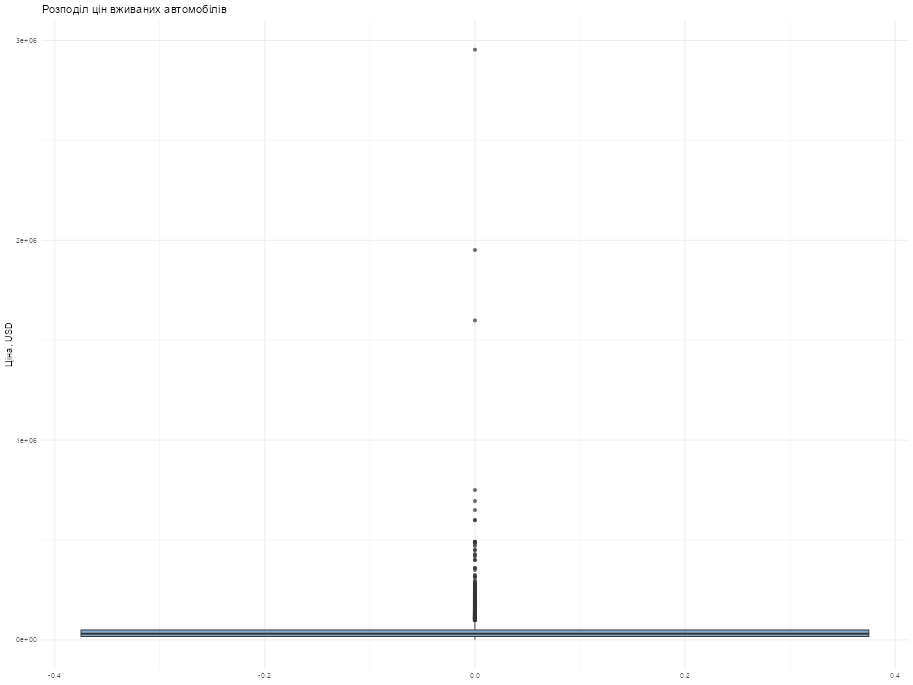

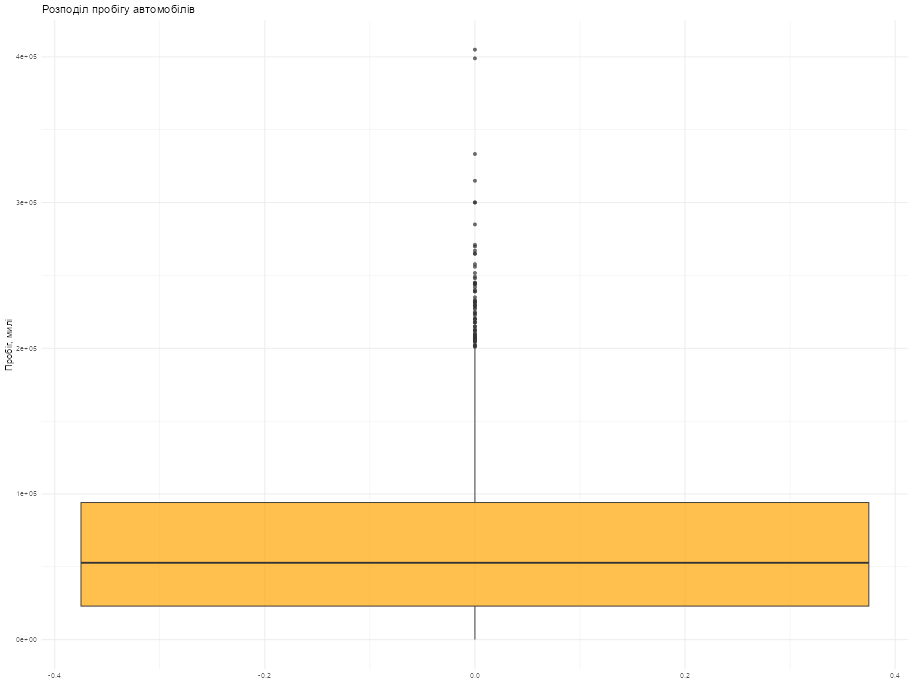

In [10]:

ggplot(cars_check, aes(y = price_num)) +
  geom_boxplot(fill = "steelblue", alpha = 0.7) +
  labs(
    title = "Розподіл цін вживаних автомобілів",
    y = "Ціна, USD",
    x = NULL
  ) +
  theme_minimal()

ggplot(cars_check, aes(y = milage_num)) +
  geom_boxplot(fill = "orange", alpha = 0.7) +
  labs(
    title = "Розподіл пробігу автомобілів",
    y = "Пробіг, милі",
    x = NULL
  ) +
  theme_minimal()


#### Після цього обчислимо кількість потенційних викидів за правилом IQR:

In [11]:

count_outliers <- function(x) {
  q1 <- quantile(x, 0.25, na.rm = TRUE)
  q3 <- quantile(x, 0.75, na.rm = TRUE)
  iqr <- q3 - q1

  sum(
    x < q1 - 1.5 * iqr |
    x > q3 + 1.5 * iqr,
    na.rm = TRUE
  )
}

cat("Викиди ціни:",
    count_outliers(cars_check$price_num), "\n")

cat("Викиди пробігу:",
    count_outliers(cars_check$milage_num), "\n")


Викиди ціни: 244 
Викиди пробігу: 69 


### 2.5. Збереження результатів перевірки

In [12]:

write_csv(
  missing_data,
  "../outputs/tables/missing_values.csv"
)

write_csv(
  quality_check,
  "../outputs/tables/quality_check.csv"
)


## Висновок

#### У наборі даних із 4 009 спостережень виявлено пропущені значення у трьох категоріальних змінних: clean_title, fuel_type та accident. Повних дублікатів не знайдено. Некоректних значень ціни, пробігу та року випуску за визначеними критеріями не виявлено.

#### За правилом IQR визначено 244 потенційні викиди ціни та 69 потенційних викидів пробігу. Розподіли мають правосторонню асиметрію. Оскільки незвичайні значення можуть відповідати реальним автомобілям, їх вирішено зберегти для подальшого аналізу.

#### Для підготовки даних необхідно перетворити ціну й пробіг на числовий формат та обробити пропуски категоріальних змінних.

## 3. Очищення та підготовка даних

### 3.1. Створюємо очищену копію

In [13]:

cars_clean <- cars_raw %>%
  mutate(
    price = readr::parse_number(price),
    milage = readr::parse_number(milage),
    across(
      c(fuel_type, accident, clean_title),
      ~ replace_na(.x, "Unknown")
    )
  )

glimpse(cars_clean)


Rows: 4,009
Columns: 12
$ brand        <chr> "Ford", "Hyundai", "Lexus", "INFINITI", "Audi", "Acura", "Audi", "BMW", "Lexus", "Tesla", "Land", "Aston", "Toyota", "L…
$ model        <chr> "Utility Police Interceptor Base", "Palisade SEL", "RX 350 RX 350", "Q50 Hybrid Sport", "Q3 45 S line Premium Plus", "I…
$ model_year   <dbl> 2013, 2021, 2022, 2015, 2021, 2016, 2017, 2001, 2021, 2020, 2021, 2019, 2021, 2022, 2020, 2013, 2021, 2013, 2003, 2018,…
$ milage       <dbl> 51000, 34742, 22372, 88900, 9835, 136397, 84000, 242000, 23436, 34000, 27608, 22770, 12500, 18196, 15903, 79800, 1685, …
$ fuel_type    <chr> "E85 Flex Fuel", "Gasoline", "Gasoline", "Hybrid", "Gasoline", "Gasoline", "Gasoline", "Gasoline", "Gasoline", "Unknown…
$ engine       <chr> "300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capability", "3.8L V6 24V GDI DOHC", "3.5 Liter DOHC", "354.0HP 3.5L V6 Cyli…
$ transmission <chr> "6-Speed A/T", "8-Speed Automatic", "Automatic", "7-Speed A/T", "8-Speed Automatic", "F", "6-Speed A/T"

#### Що змінилося:
#### - price — числовий формат замість текстового.
#### - milage — числовий формат замість текстового.
#### - Пропуски в трьох категоріальних стовпцях замінені на Unknown.

### 3.2. Перевіряємо результат очищення

In [14]:

cat("Рядків до:", nrow(cars_raw), "\n")
cat("Рядків після:", nrow(cars_clean), "\n")

colSums(is.na(cars_clean))

summary(cars_clean$price)
summary(cars_clean$milage)


Рядків до: 4009 
Рядків після: 4009 


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
    100   23044   52775   64718   94100  405000 

### 3.3. Перевіряємо категорії після очищення

In [15]:

cars_clean %>% count(fuel_type, sort = TRUE)

cars_clean %>% count(accident, sort = TRUE)

cars_clean %>% count(clean_title, sort = TRUE)


# A tibble: 2 × 2
  clean_title     n
  <chr>       <int>
1 Yes          3413
2 Unknown       596

### 3.4. Нормалізація типів пального

In [16]:

cars_clean <- cars_clean %>%
  mutate(
    fuel_type = if_else(
      fuel_type %in% c("–", "-", "not supported"),
      "Unknown",
      fuel_type
    )
  )

cars_clean %>%
  count(fuel_type, sort = TRUE)


# A tibble: 6 × 2
  fuel_type          n
  <chr>          <int>
1 Gasoline        3309
2 Unknown          217
3 Hybrid           194
4 E85 Flex Fuel    139
5 Diesel           116
6 Plug-In Hybrid    34

### 3.5. Зберігаємо очищений датасет

In [17]:

write_csv(
  cars_clean,
  "../data/processed/clean_data.csv"
)

cat("Очищений датасет збережено.\n")


Очищений датасет збережено.


### 3.6. Візуалізуємо ціни з логарифмічною шкалою

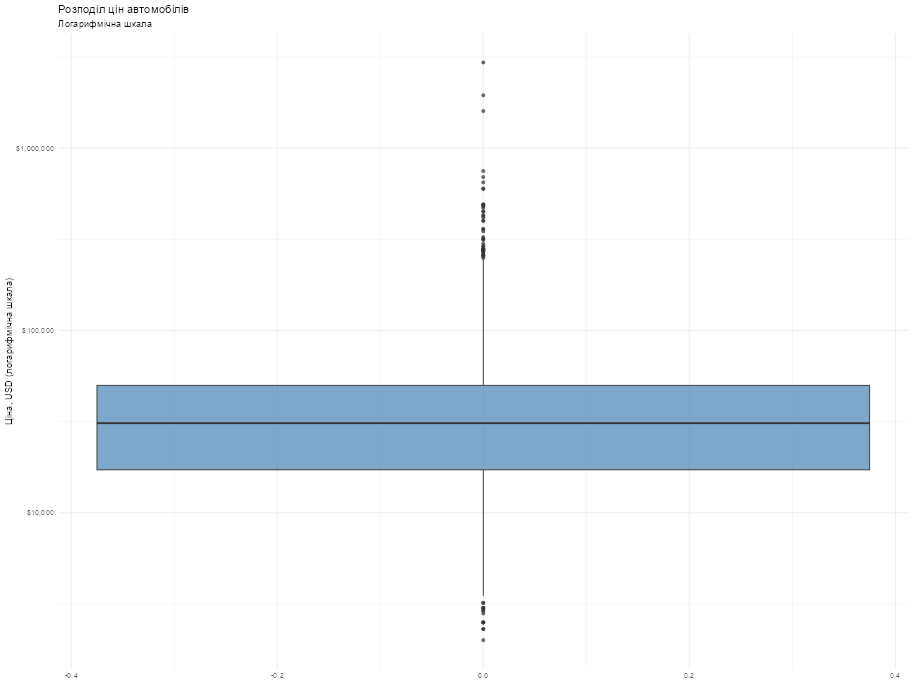

In [18]:

ggplot(cars_clean, aes(y = price)) +
  geom_boxplot(
    fill = "steelblue",
    alpha = 0.7
  ) +
  scale_y_log10(labels = scales::label_dollar()) +
  labs(
    title = "Розподіл цін автомобілів",
    subtitle = "Логарифмічна шкала",
    x = NULL,
    y = "Ціна, USD (логарифмічна шкала)"
  ) +
  theme_minimal()


## Аналіз графіка
#### На новому boxplot добре видно основний діапазон цін та окремі дуже дорогі автомобілі.

### Висновки
 #### Після очищення збережено всі 4 009 спостережень. Ціну та пробіг перетворено на числові значення, а пропуски категоріальних змінних позначено як Unknown. Логарифмічна шкала покращила візуалізацію асиметричного розподілу цін. Потенційні викиди збережено, оскільки вони можуть відповідати реальним автомобілям.

## 4. Описова статистика

### 4.1. Основні статистики числових змінних

#### Будемо досліджувати три числові змінні:
#### - price — ціна, USD.
#### - milage — пробіг, милі.
#### - model_year — рік випуску автомобіля.

In [19]:

numeric_stats <- cars_clean %>%
  select(price, milage, model_year) %>%
  pivot_longer(
    cols = everything(),
    names_to = "variable",
    values_to = "value"
  ) %>%
  group_by(variable) %>%
  summarise(
    count = sum(!is.na(value)),
    mean = mean(value, na.rm = TRUE),
    median = median(value, na.rm = TRUE),
    sd = sd(value, na.rm = TRUE),
    min = min(value, na.rm = TRUE),
    q1 = quantile(value, 0.25, na.rm = TRUE),
    q3 = quantile(value, 0.75, na.rm = TRUE),
    max = max(value, na.rm = TRUE),
    .groups = "drop"
  )

print(numeric_stats)


# A tibble: 3 × 9
  variable   count   mean median       sd   min    q1    q3     max
  <chr>      <int>  <dbl>  <dbl>    <dbl> <dbl> <dbl> <dbl>   <dbl>
1 milage      4009 64718.  52775 52297.     100 23044 94100  405000
2 model_year  4009  2016.   2017     6.10  1974  2012  2020    2024
3 price       4009 44553.  31000 78711.    2000 17200 49990 2954083


#### Що обчислюємо:

| Показник | Значення |
|----------|----------|
| count  | Кількість значень |
| mean  | Середнє арифметичне |
| median | Медіана — центральне значення |
| sd     | Стандартне відхилення |
| min    | Мінімальне значення |
| max    | Максимальне значення |
| q1     | Перший квартиль (25%) |
| q3     | Третій квартиль (75%) |

#### Ця таблиця допоможе порівняти середні та медіанні значення і визначити мінливість характеристик автомобілів.

### 4.2. Аналіз марок автомобілів

#### Перевіримо, які марки найчастіше зустрічаються в датасеті.

In [20]:

brand_stats <- cars_clean %>%
  count(brand, sort = TRUE) %>%
  mutate(
    percent = round(n / sum(n) * 100, 2)
  )

print(head(brand_stats, 15))


# A tibble: 15 × 3
   brand             n percent
   <chr>         <int>   <dbl>
 1 Ford            386    9.63
 2 BMW             375    9.35
 3 Mercedes-Benz   315    7.86
 4 Chevrolet       292    7.28
 5 Porsche         201    5.01
 6 Audi            200    4.99
 7 Toyota          199    4.96
 8 Lexus           163    4.07
 9 Jeep            143    3.57
10 Land            130    3.24
11 Nissan          116    2.89
12 Cadillac        107    2.67
13 GMC              91    2.27
14 RAM              91    2.27
15 Dodge            90    2.24


#### Побудуємо графік:

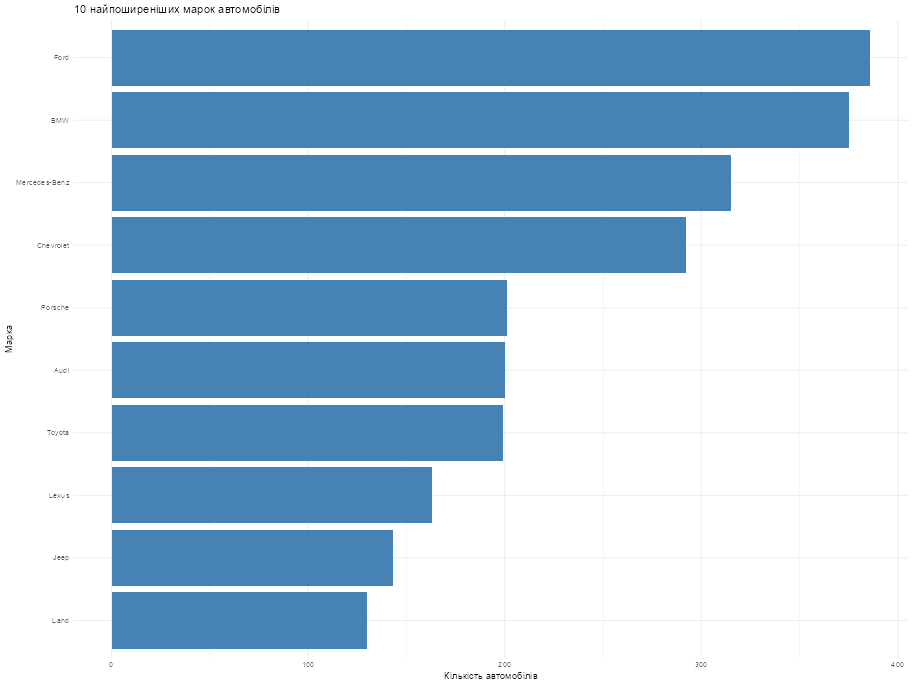

In [21]:

ggplot(
  head(brand_stats, 10),
  aes(x = reorder(brand, n), y = n)
) +
  geom_col(fill = "steelblue") +
  coord_flip() +
  labs(
    title = "10 найпоширеніших марок автомобілів",
    x = "Марка",
    y = "Кількість автомобілів"
  ) +
  theme_minimal()


#### Результат покаже 15 найпоширеніших марок автомобілів, кількість записів та їхню частку.

### 4.3. Аналіз типів пального

In [22]:

fuel_stats <- cars_clean %>%
  count(fuel_type, sort = TRUE) %>%
  mutate(
    percent = round(n / sum(n) * 100, 2)
  )

print(fuel_stats)


# A tibble: 6 × 3
  fuel_type          n percent
  <chr>          <int>   <dbl>
1 Gasoline        3309   82.5 
2 Unknown          217    5.41
3 Hybrid           194    4.84
4 E85 Flex Fuel    139    3.47
5 Diesel           116    2.89
6 Plug-In Hybrid    34    0.85


#### Побудуємо графік:

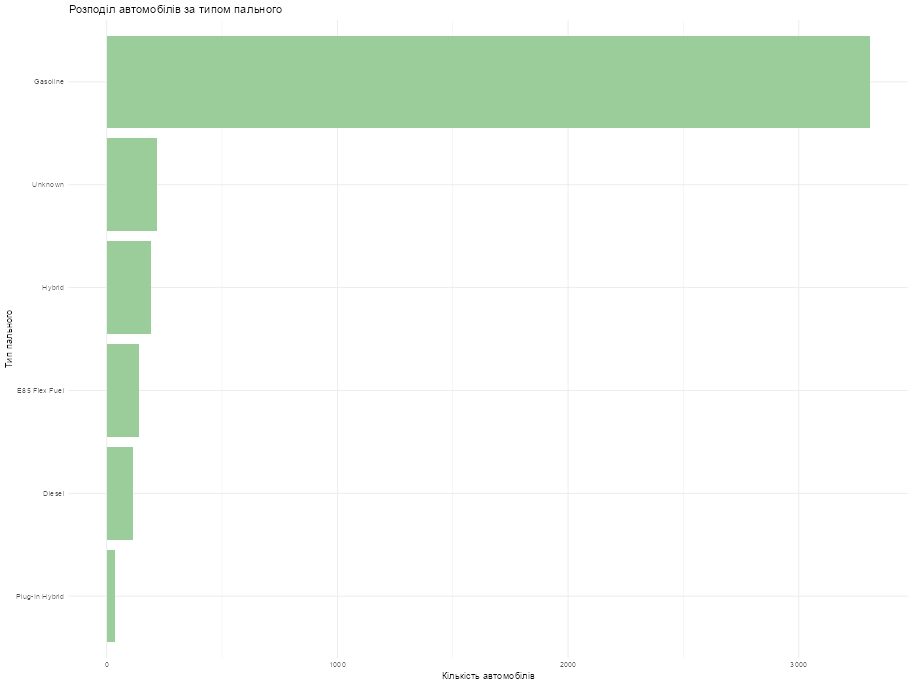

In [23]:

ggplot(
  fuel_stats,
  aes(x = reorder(fuel_type, n), y = n)
) +
  geom_col(fill = "darkseagreen3") +
  coord_flip() +
  labs(
    title = "Розподіл автомобілів за типом пального",
    x = "Тип пального",
    y = "Кількість автомобілів"
  ) +
  theme_minimal()


#### Це дозволить визначити, які типи пального переважають у вибірці.

### 4.4. Аналіз історії ДТП

In [24]:

accident_stats <- cars_clean %>%
  count(accident, sort = TRUE) %>%
  mutate(
    percent = round(n / sum(n) * 100, 2)
  )

print(accident_stats)


# A tibble: 3 × 3
  accident                                   n percent
  <chr>                                  <int>   <dbl>
1 None reported                           2910   72.6 
2 At least 1 accident or damage reported   986   24.6 
3 Unknown                                  113    2.82


#### Ця таблиця покаже частку автомобілів із зафіксованими ДТП, без повідомлень про пошкодження та з невідомою історією.

### 4.5. Зберігаємо результати статистики

In [25]:

write_csv(
  numeric_stats,
  "../outputs/tables/descriptive_statistics.csv"
)

write_csv(
  brand_stats,
  "../outputs/tables/brand_statistics.csv"
)

write_csv(
  fuel_stats,
  "../outputs/tables/fuel_statistics.csv"
)

write_csv(
  accident_stats,
  "../outputs/tables/accident_statistics.csv"
)


### Також збережемо два графіки для майбутньої презентації.

#### 1. Збереження графіка марок автомобілів

In [26]:
p_brand <- ggplot(
  head(brand_stats, 10),
  aes(x = reorder(brand, n), y = n)
) +
  geom_col(fill = "steelblue") +
  coord_flip() +
  labs(
    title = "10 найпоширеніших марок автомобілів",
    x = "Марка",
    y = "Кількість автомобілів"
  ) +
  theme_minimal()

ggsave(
  "../outputs/figures/brand_distribution.png",
  plot = p_brand,
  width = 9,
  height = 6,
  dpi = 300
)

#### 2. Збереження графіка типів пального — p_fuel

In [27]:

p_fuel <- ggplot(
  fuel_stats,
  aes(x = reorder(fuel_type, n), y = n)
) +
  geom_col(fill = "darkseagreen3") +
  coord_flip() +
  labs(
    title = "Розподіл автомобілів за типом пального",
    x = "Тип пального",
    y = "Кількість автомобілів"
  ) +
  theme_minimal()

ggsave(
  "../outputs/figures/fuel_distribution.png",
  plot = p_fuel,
  width = 9,
  height = 6,
  dpi = 300
)


### Висновок 

#### Описова статистика показала, що середня ціна автомобіля становить приблизно 44,6 тис. доларів, а медіанна — 31 тис. доларів. Це свідчить про правосторонню асиметрію розподілу цін. Середній пробіг становить приблизно 64,7 тис. миль, а медіанний рік випуску — 2017.

#### Найпоширенішими марками є Ford, BMW та Mercedes-Benz. Переважна більшість автомобілів використовує бензин. У 24,6% записів зазначено щонайменше одну ДТП або пошкодження.

#### Отримані результати підтверджують доцільність подальшого аналізу зв'язків між ціною, пробігом, роком випуску, маркою та історією ДТП.

## 5. Одновимірний аналіз

#### Метою цього етапу є дослідження розподілів ціни, пробігу та року випуску автомобілів, визначення асиметрії та особливостей числових характеристик.

### 5.1. Аналіз розподілу цін автомобілів

#### Побудуємо гістограму цільової змінної price.

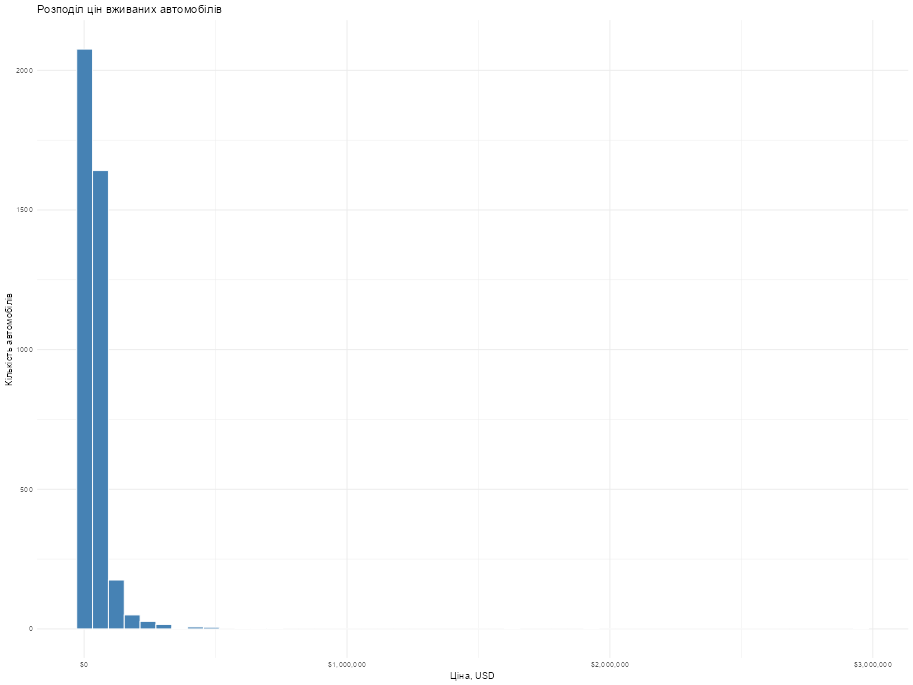

In [28]:

p_price <- ggplot(cars_clean, aes(x = price)) +
  geom_histogram(
    bins = 50,
    fill = "steelblue",
    color = "white"
  ) +
  scale_x_continuous(
    labels = scales::label_dollar()
  ) +
  labs(
    title = "Розподіл цін вживаних автомобілів",
    x = "Ціна, USD",
    y = "Кількість автомобілів"
  ) +
  theme_minimal()

p_price


### 5.2. Розподіл цін із логарифмічною шкалою

#### Щоб краще дослідити основну частину розподілу, побудуємо гістограму з логарифмічною шкалою.

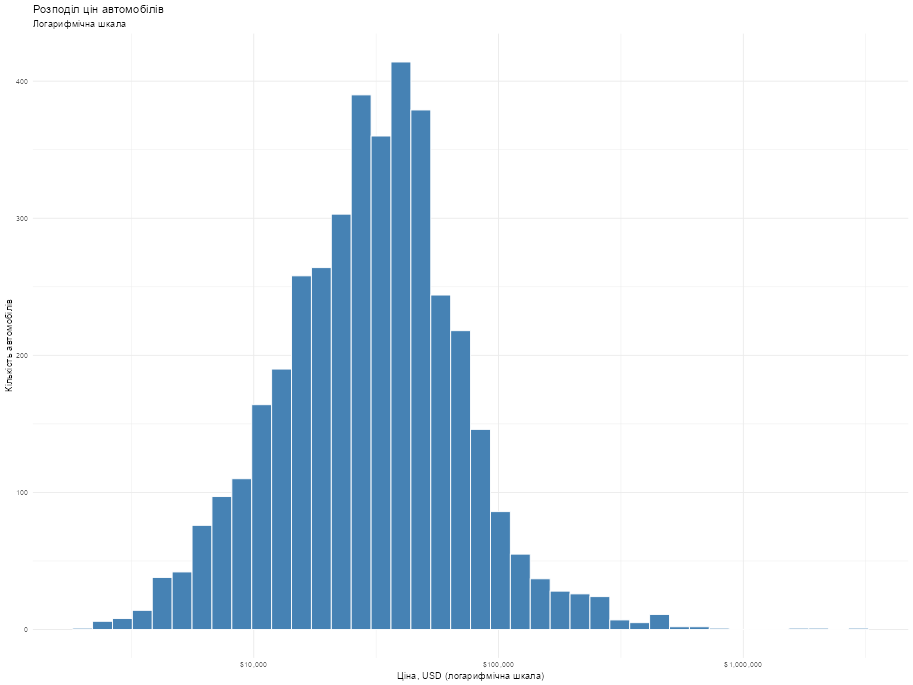

In [29]:

p_price_log <- ggplot(cars_clean, aes(x = price)) +
  geom_histogram(
    bins = 40,
    fill = "steelblue",
    color = "white"
  ) +
  scale_x_log10(
    labels = scales::label_dollar()
  ) +
  labs(
    title = "Розподіл цін автомобілів",
    subtitle = "Логарифмічна шкала",
    x = "Ціна, USD (логарифмічна шкала)",
    y = "Кількість автомобілів"
  ) +
  theme_minimal()

p_price_log


### 5.3. Аналіз розподілу пробігу

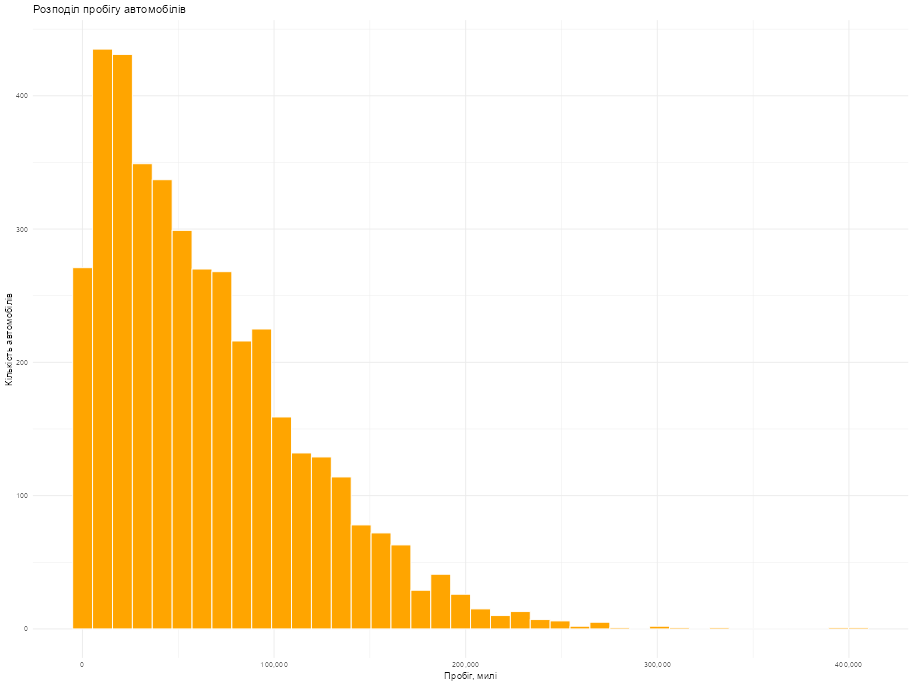

In [30]:

p_milage <- ggplot(cars_clean, aes(x = milage)) +
  geom_histogram(
    bins = 40,
    fill = "orange",
    color = "white"
  ) +
  scale_x_continuous(
    labels = scales::label_comma()
  ) +
  labs(
    title = "Розподіл пробігу автомобілів",
    x = "Пробіг, милі",
    y = "Кількість автомобілів"
  ) +
  theme_minimal()

p_milage


### 5.4. Аналіз року випуску автомобілів

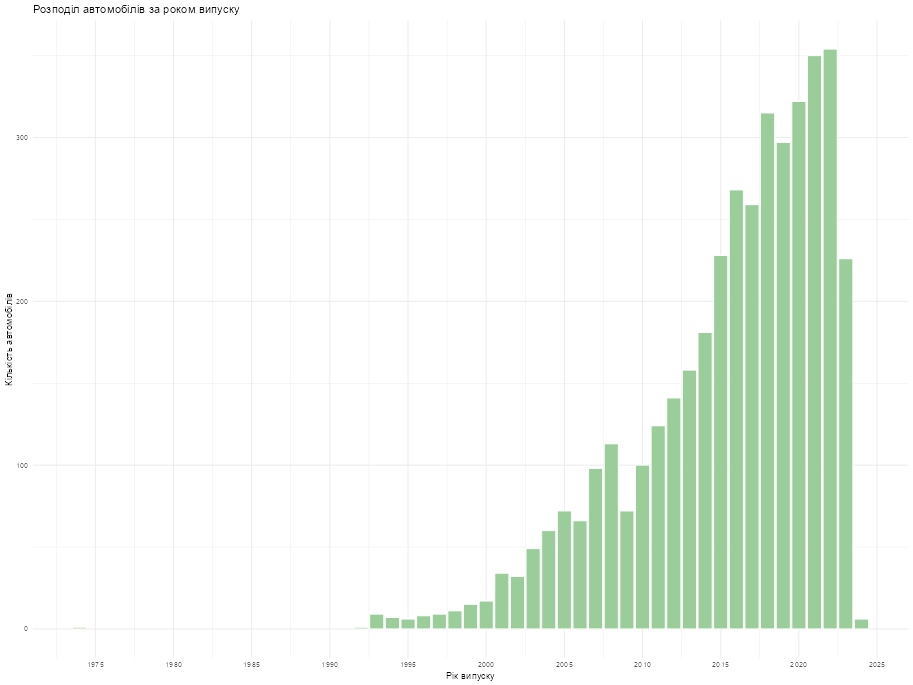

In [31]:

p_year <- ggplot(cars_clean, aes(x = model_year)) +
  geom_bar(
    fill = "darkseagreen3",
    color = "white"
  ) +
  scale_x_continuous(
    breaks = seq(1970, 2025, by = 5)
  ) +
  labs(
    title = "Розподіл автомобілів за роком випуску",
    x = "Рік випуску",
    y = "Кількість автомобілів"
  ) +
  theme_minimal()

p_year


### 5.5. Оцінка асиметрії розподілів

#### Щоб не лише візуально, а й чисельно оцінити асиметрію, обчислимо коефіцієнт асиметрії (skewness).

In [32]:

skewness <- function(x) {
  x <- x[!is.na(x)]
  mean((x - mean(x))^3) /
    mean((x - mean(x))^2)^(3/2)
}

skewness_stats <- tibble(
  variable = c("price", "milage", "model_year"),
  skewness = c(
    skewness(cars_clean$price),
    skewness(cars_clean$milage),
    skewness(cars_clean$model_year)
  )
)

print(skewness_stats)


# A tibble: 3 × 2
  variable   skewness
  <chr>         <dbl>
1 price         19.5 
2 milage         1.16
3 model_year    -1.09


### 5.6. Збереження результатів одновимірного аналізу

In [33]:

ggsave(
  "../outputs/figures/price_distribution.png",
  plot = p_price,
  width = 9, height = 6, dpi = 300
)

ggsave(
  "../outputs/figures/price_log_distribution.png",
  plot = p_price_log,
  width = 9, height = 6, dpi = 300
)

ggsave(
  "../outputs/figures/milage_distribution.png",
  plot = p_milage,
  width = 9, height = 6, dpi = 300
)

ggsave(
  "../outputs/figures/year_distribution.png",
  plot = p_year,
  width = 9, height = 6, dpi = 300
)

write_csv(
  skewness_stats,
  "../outputs/tables/skewness_statistics.csv"
)


### Висновок одновимірного аналізу

#### Одновимірний аналіз показав, що всі три числові змінні мають асиметричні розподіли. Найбільша асиметрія спостерігається у ціни автомобілів (19,5), що пояснюється наявністю надзвичайно дорогих автомобілів. Використання логарифмічної шкали дозволило краще відобразити основну частину розподілу.

#### Пробіг має правосторонню асиметрію (1,16), оскільки у вибірці переважають автомобілі з невеликим та середнім пробігом. Рік випуску має лівосторонню асиметрію (-1,09), що свідчить про переважання відносно нових автомобілів.

#### Через асиметричність розподілів для порівняння груп автомобілів доцільно використовувати не лише середні значення, а й медіани.

### 6. Двовимірний аналіз

#### Метою цього етапу є дослідження зв'язків між ціноюавтомобілів та їхніми числовими й категоріальними характеристиками, визначення напрямку, силита форми цих зв'язків.

### 6.1. Залежність ціни від пробігу

#### Побудуємо діаграму розсіювання

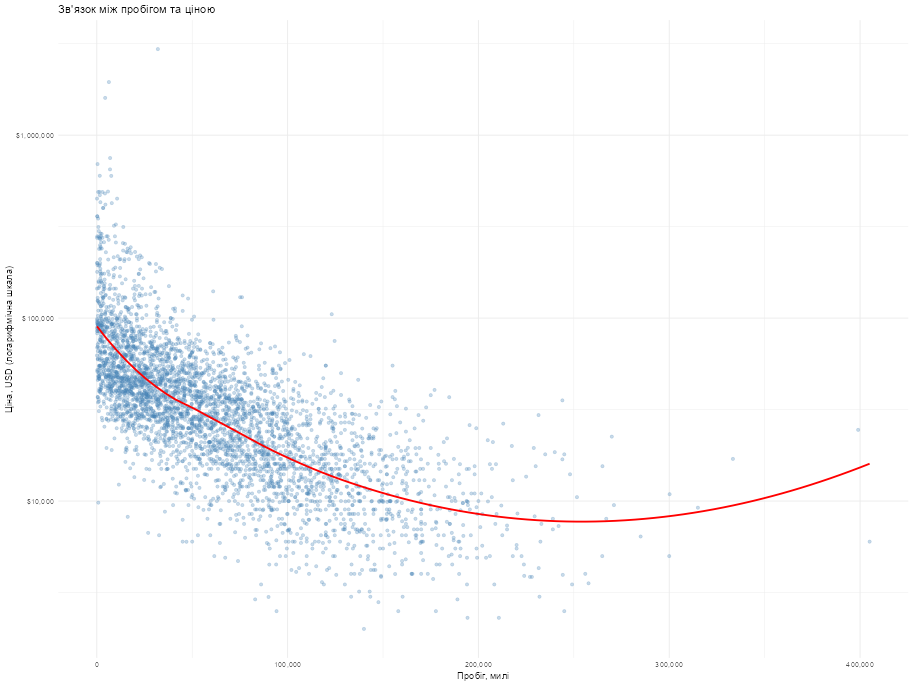

In [34]:

p_price_milage <- ggplot(
  cars_clean,
  aes(x = milage, y = price)
) +
  geom_point(
    alpha = 0.3,
    color = "steelblue"
  ) +
  geom_smooth(
    method = "loess",
    formula = y ~ x,
    se = FALSE,
    color = "red"
  ) +
  scale_x_continuous(
    labels = scales::label_comma()
  ) +
  scale_y_log10(
    labels = scales::label_dollar()
  ) +
  labs(
    title = "Зв'язок між пробігом та ціною",
    x = "Пробіг, милі",
    y = "Ціна, USD (логарифмічна шкала)"
  ) +
  theme_minimal()

p_price_milage


### 6.2. Залежність ціни від року випуску

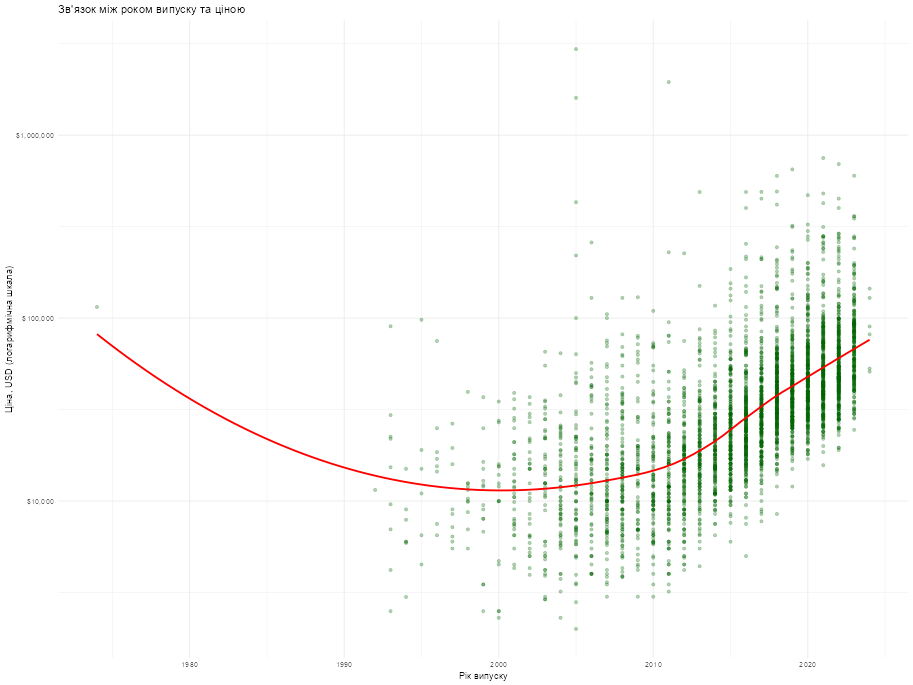

In [35]:

p_price_year <- ggplot(
  cars_clean,
  aes(x = model_year, y = price)
) +
  geom_point(
    alpha = 0.3,
    color = "darkgreen"
  ) +
  geom_smooth(
    method = "loess",
    formula = y ~ x,
    se = FALSE,
    color = "red"
  ) +
  scale_y_log10(
    labels = scales::label_dollar()
  ) +
  labs(
    title = "Зв'язок між роком випуску та ціною",
    x = "Рік випуску",
    y = "Ціна, USD (логарифмічна шкала)"
  ) +
  theme_minimal()

p_price_year


### 6.3. Обчислення кореляцій

#### Для числової оцінки зв'язків використаємо два коефіцієнти кореляції:
| Метод | Що визначає |
|---|---|
| Pearson | Силу та напрям лінійного зв'язку |
| Spearman | Силу та напрям монотонного зв'язку за рангами |

In [36]:

correlation_pairs <- tibble(
  factor = c("milage", "model_year"),

  pearson = c(
    cor(cars_clean$price,
        cars_clean$milage,
        method = "pearson"),

    cor(cars_clean$price,
        cars_clean$model_year,
        method = "pearson")
  ),

  spearman = c(
    cor(cars_clean$price,
        cars_clean$milage,
        method = "spearman"),

    cor(cars_clean$price,
        cars_clean$model_year,
        method = "spearman")
  )
)

print(correlation_pairs)


# A tibble: 2 × 3
  factor     pearson spearman
  <chr>        <dbl>    <dbl>
1 milage      -0.306   -0.755
2 model_year   0.199    0.697


### 6.4. Залежність ціни від марки автомобіля

#### Для порівняння використаємо 10 найпоширеніших марок, щоб уникнути перевантаження графіка та порівняння надто малих груп.

#### Спочатку сформуємо таблицю:

In [37]:

top_brands <- head(brand_stats$brand, 10)

brand_price_stats <- cars_clean %>%
  filter(brand %in% top_brands) %>%
  group_by(brand) %>%
  summarise(
    count = n(),
    mean_price = mean(price),
    median_price = median(price),
    sd_price = sd(price),
    .groups = "drop"
  ) %>%
  arrange(desc(median_price))

print(brand_price_stats)


# A tibble: 10 × 5
   brand         count mean_price median_price sd_price
   <chr>         <int>      <dbl>        <dbl>    <dbl>
 1 Porsche         201     88751.       59900   126217.
 2 Land            130     55764.       44924    42240.
 3 Mercedes-Benz   315     52076.       38598    50112.
 4 Audi            200     39907.       34498.   29983.
 5 BMW             375     41072.       32999    27273.
 6 Ford            386     36241.       32378.   29439.
 7 Chevrolet       292     36723.       31992.   25487.
 8 Jeep            143     31100.       30000    17744.
 9 Lexus           163     35669.       30000    25912.
10 Toyota          199     30026        27999    19332.


#### Тепер побудуємо boxplot:

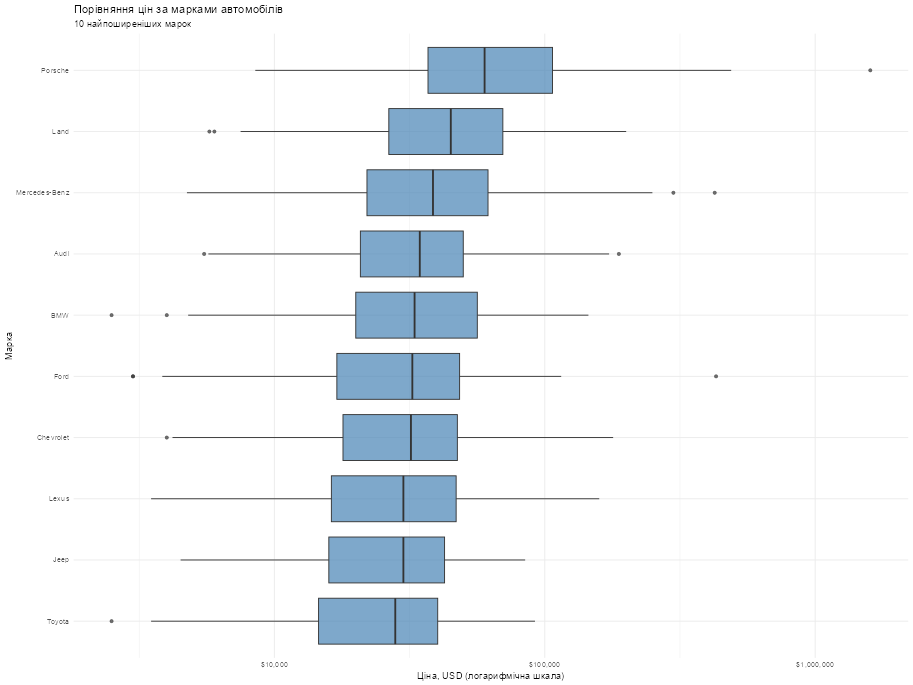

In [38]:

p_price_brand <- cars_clean %>%
  filter(brand %in% top_brands) %>%
  ggplot(
    aes(
      x = reorder(brand, price, FUN = median),
      y = price
    )
  ) +
  geom_boxplot(
    fill = "steelblue",
    alpha = 0.7
  ) +
  scale_y_log10(
    labels = scales::label_dollar()
  ) +
  coord_flip() +
  labs(
    title = "Порівняння цін за марками автомобілів",
    subtitle = "10 найпоширеніших марок",
    x = "Марка",
    y = "Ціна, USD (логарифмічна шкала)"
  ) +
  theme_minimal()

p_price_brand


#### За допомогою цього графіка визначвємо, які марки мають вищі медіанні ціни та більшу мінливість.

### 6.5. Залежність ціни від типу пального

#### Створимо таблицю групових статистик.

In [39]:

fuel_price_stats <- cars_clean %>%
  group_by(fuel_type) %>%
  summarise(
    count = n(),
    mean_price = mean(price),
    median_price = median(price),
    sd_price = sd(price),
    .groups = "drop"
  ) %>%
  arrange(desc(median_price))

print(fuel_price_stats)


# A tibble: 6 × 5
  fuel_type      count mean_price median_price sd_price
  <chr>          <int>      <dbl>        <dbl>    <dbl>
1 Hybrid           194     51426.        45499   32417.
2 Diesel           116     48695.        45450   27381.
3 Plug-In Hybrid    34     45946.        44945   22843.
4 Unknown          217     50170.        43000   47447.
5 Gasoline        3309     44539.        29950   85052.
6 E85 Flex Fuel    139     22744.        19500   13408.


#### Побудуємо графік:

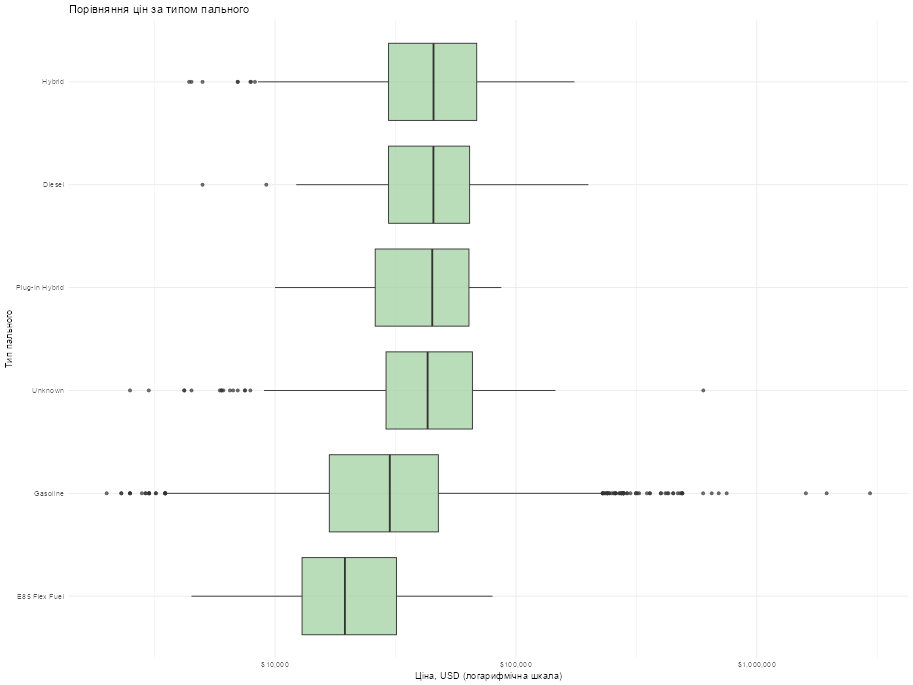

In [40]:

p_price_fuel <- ggplot(
  cars_clean,
  aes(
    x = reorder(fuel_type, price, FUN = median),
    y = price
  )
) +
  geom_boxplot(
    fill = "darkseagreen3",
    alpha = 0.7
  ) +
  scale_y_log10(
    labels = scales::label_dollar()
  ) +
  coord_flip() +
  labs(
    title = "Порівняння цін за типом пального",
    x = "Тип пального",
    y = "Ціна, USD (логарифмічна шкала)"
  ) +
  theme_minimal()

p_price_fuel


### 6.6. Залежність ціни від історії ДТП

#### Перевіримо, як відрізняється ціна автомобілів залежно від наявності повідомлень про ДТП або пошкодження.

In [41]:

accident_price_stats <- cars_clean %>%
  group_by(accident) %>%
  summarise(
    count = n(),
    mean_price = mean(price),
    median_price = median(price),
    sd_price = sd(price),
    .groups = "drop"
  ) %>%
  arrange(desc(median_price))

print(accident_price_stats)


# A tibble: 3 × 5
  accident                               count mean_price median_price sd_price
  <chr>                                  <int>      <dbl>        <dbl>    <dbl>
1 Unknown                                  113     50788.       36500    45260.
2 None reported                           2910     49638.       35668.   72554.
3 At least 1 accident or damage reported   986     28832.       20900    95402.


####  Побудуємо графік:

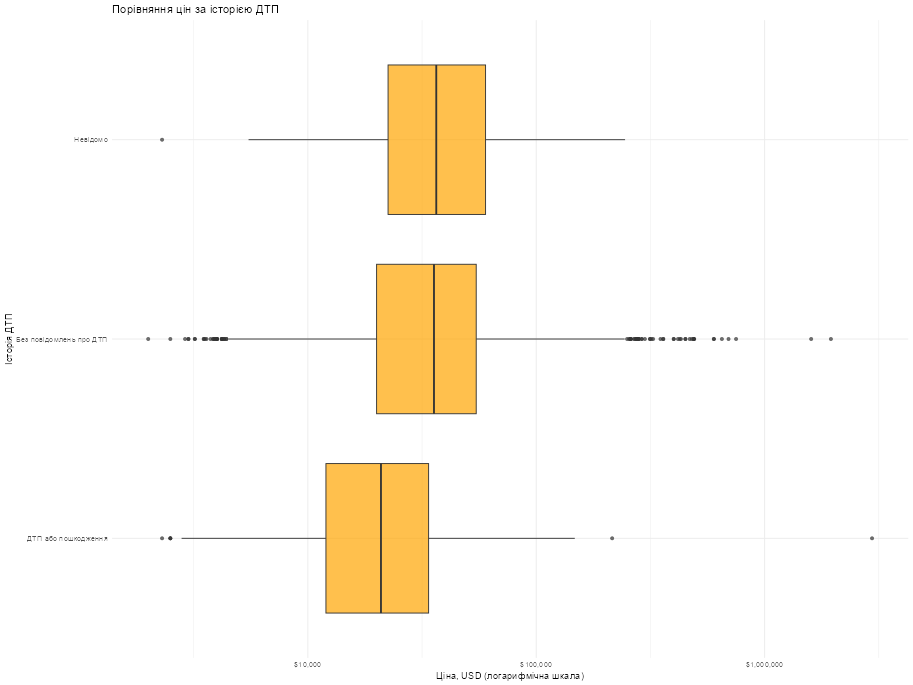

In [42]:

p_price_accident <- ggplot(
  cars_clean,
  aes(
    x = reorder(accident, price, FUN = median),
    y = price
  )
) +
  geom_boxplot(
    fill = "orange",
    alpha = 0.7
  ) +
  scale_y_log10(
    labels = scales::label_dollar()
  ) +
  scale_x_discrete(
    labels = c(
      "None reported" = "Без повідомлень про ДТП",
      "At least 1 accident or damage reported" =
        "ДТП або пошкодження",
      "Unknown" = "Невідомо"
    )
  ) +
  coord_flip() +
  labs(
    title = "Порівняння цін за історією ДТП",
    x = "Історія ДТП",
    y = "Ціна, USD (логарифмічна шкала)"
  ) +
  theme_minimal()

p_price_accident


#### Додатково обчислимо відсоткову різницю медіанних цін автомобілів із повідомленнями про ДТП та без них.

In [43]:

median_no_accident <- cars_clean %>%
  filter(accident == "None reported") %>%
  summarise(value = median(price)) %>%
  pull(value)

median_accident <- cars_clean %>%
  filter(
    accident == "At least 1 accident or damage reported"
  ) %>%
  summarise(value = median(price)) %>%
  pull(value)

price_difference <- (
  (median_no_accident - median_accident) /
    median_no_accident
) * 100

cat(
  "Різниця медіанних цін:",
  round(price_difference, 2),
  "%\n"
)


Різниця медіанних цін: 41.4 %


#### Цей результат покаже відносну різницю медіанних цін між групами

### 6.7. Збереження результатів двовимірного аналізу

#### Зберігаємо таблиці:

In [44]:

write_csv(
  correlation_pairs,
  "../outputs/tables/correlation_pairs.csv"
)

write_csv(
  brand_price_stats,
  "../outputs/tables/brand_price_statistics.csv"
)

write_csv(
  fuel_price_stats,
  "../outputs/tables/fuel_price_statistics.csv"
)

write_csv(
  accident_price_stats,
  "../outputs/tables/accident_price_statistics.csv"
)


#### Зберігаємо графіки:

In [45]:
ggsave(
  "../outputs/figures/price_milage.png",
  plot = p_price_milage,
  width = 9, height = 6, dpi = 300
)

ggsave(
  "../outputs/figures/price_year.png",
  plot = p_price_year,
  width = 9, height = 6, dpi = 300
)

ggsave(
  "../outputs/figures/price_brand.png",
  plot = p_price_brand,
  width = 9, height = 6, dpi = 300
)

ggsave(
  "../outputs/figures/price_fuel.png",
  plot = p_price_fuel,
  width = 9, height = 6, dpi = 300
)

ggsave(
  "../outputs/figures/price_accident.png",
  plot = p_price_accident,
  width = 9, height = 6, dpi = 300
)


### Висновок
#### Двовимірний аналіз виявив суттєві зв'язки між ціною автомобілів та їхніми характеристиками. Найсильніший монотонний зв'язок серед досліджених числових факторів спостерігається між ціною та пробігом (кореляція Спірмена −0,755). Рік випуску також має виражений додатний зв'язок із ціною (0,697).

#### Серед десяти найпоширеніших марок найвищу медіанну ціну має Porsche, а найнижчу — Toyota. Гібридні та дизельні автомобілі мають вищі медіанні ціни порівняно з бензиновими.

#### Медіанна ціна автомобілів із повідомленнями про ДТП або пошкодження на 41,4% нижча, ніж у групі без таких повідомлень.

#### Отримані результати характеризують статистичні зв'язки, але не доводять причинного впливу окремих факторів. Для детальнішого дослідження необхідно враховувати декілька характеристик одночасно.

## 7. Багатовимірний аналіз (Multivariate EDA)

#### Метою цього етапу є дослідження взаємозв'язків між числовими характеристиками автомобілів,спільних закономірностей кількох факторів та відмінностей між підгрупами.

### 7.1. Кореляційна матриця

#### Створимо дві кореляційні матриці

In [46]:

numeric_data <- cars_clean %>%
  select(price, milage, model_year)

cor_pearson <- cor(
  numeric_data,
  method = "pearson"
)

cor_spearman <- cor(
  numeric_data,
  method = "spearman"
)

print(round(cor_pearson, 3))
print(round(cor_spearman, 3))


            price milage model_year
price       1.000 -0.306      0.199
milage     -0.306  1.000     -0.618
model_year  0.199 -0.618      1.000
            price milage model_year
price       1.000 -0.755      0.697
milage     -0.755  1.000     -0.724
model_year  0.697 -0.724      1.000


#### Візуалізація кореляційної матриці

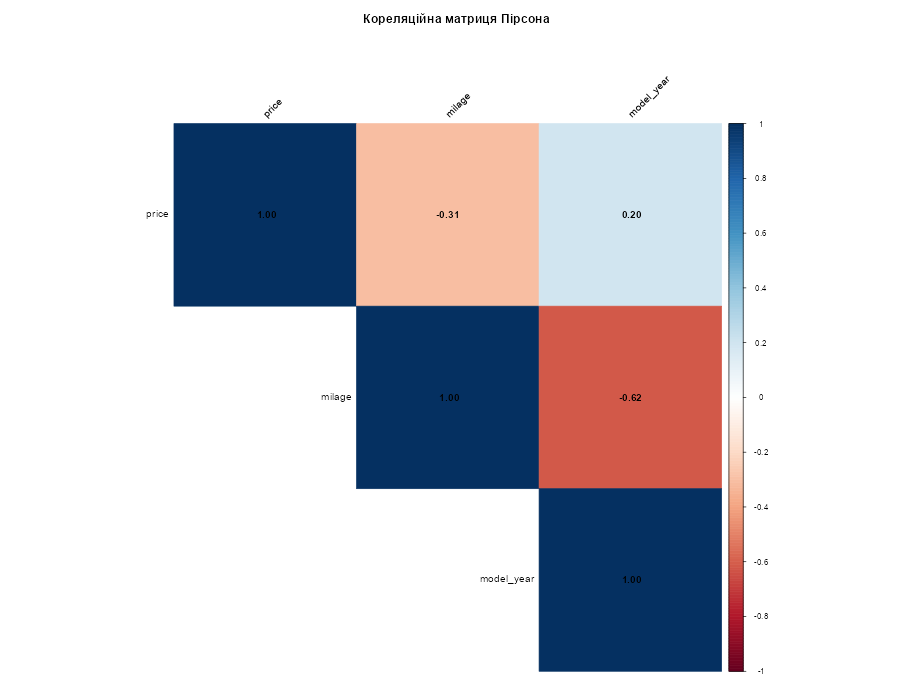

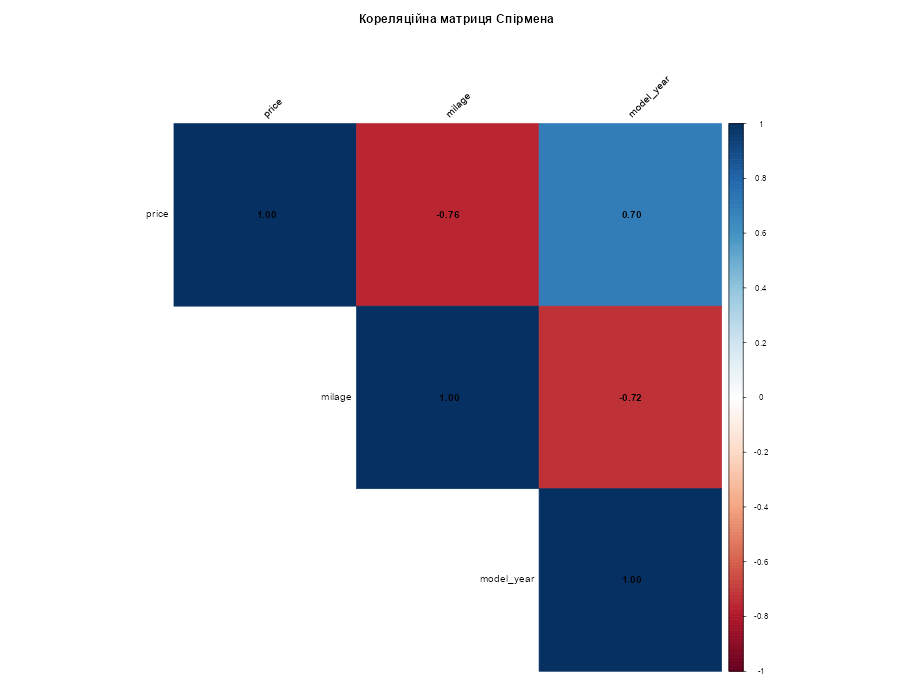

In [47]:

corrplot(
  cor_pearson,
  method = "color",
  type = "upper",
  addCoef.col = "black",
  tl.col = "black",
  tl.srt = 45,
  number.digits = 2,
  title = "Кореляційна матриця Пірсона",
  mar = c(0, 0, 3, 0)
)

corrplot(
  cor_spearman,
  method = "color",
  type = "upper",
  addCoef.col = "black",
  tl.col = "black",
  tl.srt = 45,
  number.digits = 2,
  title = "Кореляційна матриця Спірмена",
  mar = c(0, 0, 3, 0)
)


### 7.2. Спільний аналіз ціни, пробігу та року випуску

#### Для зручності розділено автомобілі на чотири групи за роком випуску

In [48]:

cars_multi <- cars_clean %>%
  mutate(
    year_group = cut(
      model_year,
      breaks = c(1900, 2009, 2014, 2019, 2024),
      labels = c(
        "До 2010",
        "2010–2014",
        "2015–2019",
        "2020–2024"
      ),
      include.lowest = TRUE
    )
  )

cars_multi %>%
  count(year_group)


# A tibble: 4 × 2
  year_group     n
  <fct>      <int>
1 До 2010      680
2 2010–2014    704
3 2015–2019   1367
4 2020–2024   1258

#### Межі груп обрано для зручного порівняння різних поколінь автомобілів.

### Побудуємо діаграму розсіювання з кольоровим розділенням за групами.

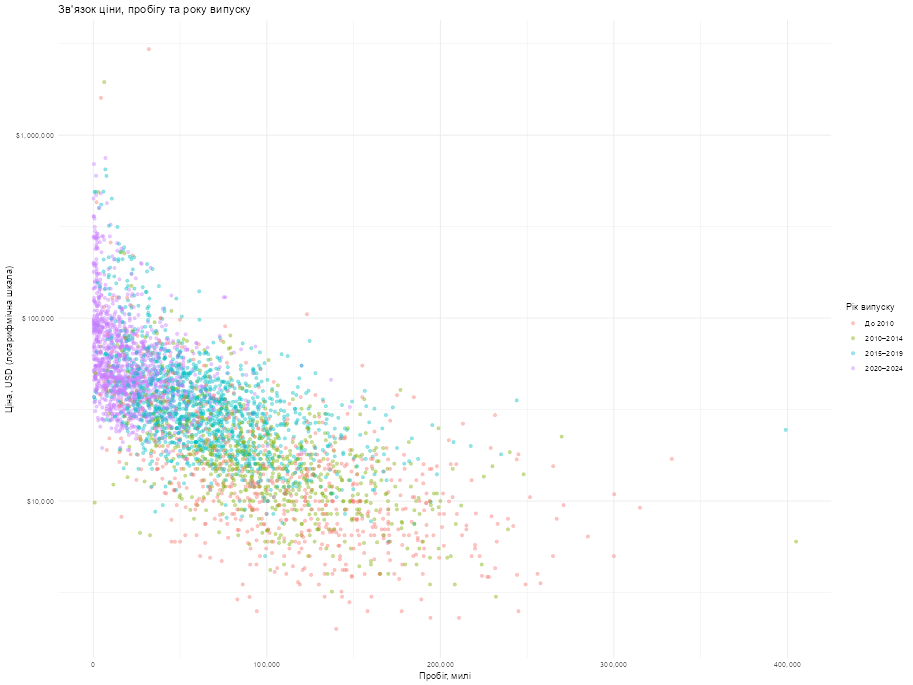

In [49]:

p_multi_milage <- ggplot(
  cars_multi,
  aes(
    x = milage,
    y = price,
    color = year_group
  )
) +
  geom_point(alpha = 0.4, size = 1.5) +
  scale_x_continuous(
    labels = scales::label_comma()
  ) +
  scale_y_log10(
    labels = scales::label_dollar()
  ) +
  labs(
    title = "Зв'язок ціни, пробігу та року випуску",
    x = "Пробіг, милі",
    y = "Ціна, USD (логарифмічна шкала)",
    color = "Рік випуску"
  ) +
  theme_minimal()

p_multi_milage


#### Тут одночасно досліджуємо три змінні:
#### - Вісь X — пробіг.
#### - Вісь Y — ціна.
#### - Колір — група року випуску.

#### Це дозволить побачити, чи відрізняються ціни автомобілів різних років випуску за приблизно однакового пробігу.

### 7.3. Аналіз ціни за роком випуску та історією ДТП

In [50]:

accident_year_stats <- cars_multi %>%
  filter(accident != "Unknown") %>%
  group_by(year_group, accident) %>%
  summarise(
    count = n(),
    median_price = median(price),
    median_milage = median(milage),
    .groups = "drop"
  )

print(accident_year_stats)


# A tibble: 8 × 5
  year_group accident                               count median_price median_milage
  <fct>      <chr>                                  <int>        <dbl>         <dbl>
1 До 2010    At least 1 accident or damage reported   228       10000        139225 
2 До 2010    None reported                            430       13275         94223 
3 2010–2014  At least 1 accident or damage reported   260       15000        103733 
4 2010–2014  None reported                            424       17500         88700 
5 2015–2019  At least 1 accident or damage reported   382       26500.        67742.
6 2015–2019  None reported                            961       34000         54423 
7 2020–2024  At least 1 accident or damage reported   116       41450         30602.
8 2020–2024  None reported                           1095       51000         16113 


### Будуємо групову стовпчикову діаграму:

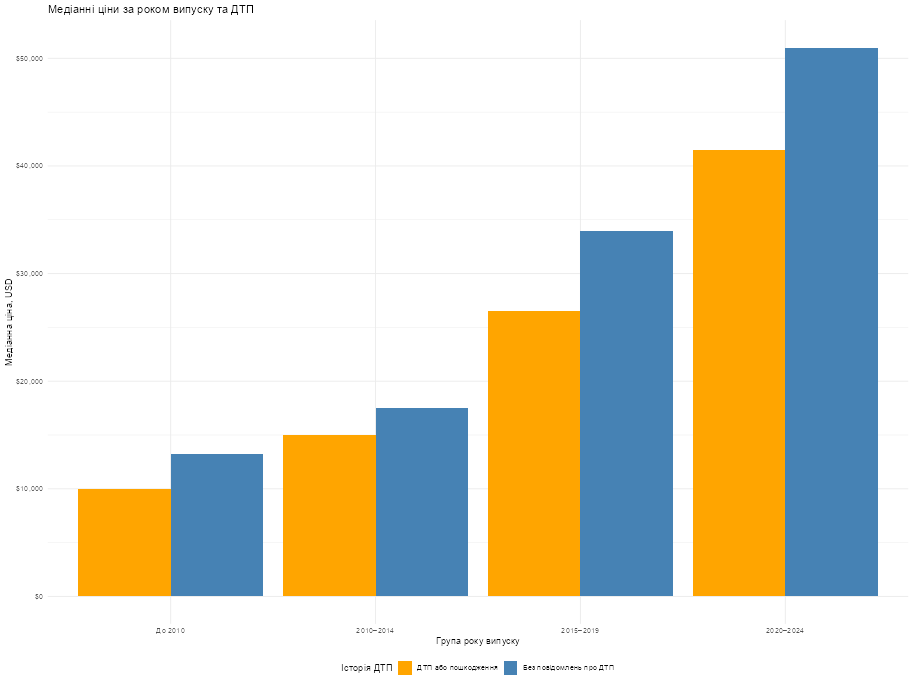

In [51]:

p_accident_year <- ggplot(
  accident_year_stats,
  aes(
    x = year_group,
    y = median_price,
    fill = accident
  )
) +
  geom_col(position = "dodge") +
  scale_y_continuous(
    labels = scales::label_dollar()
  ) +
  scale_fill_manual(
    values = c(
      "None reported" = "steelblue",
      "At least 1 accident or damage reported" =
        "orange"
    ),
    labels = c(
      "None reported" = "Без повідомлень про ДТП",
      "At least 1 accident or damage reported" =
        "ДТП або пошкодження"
    )
  ) +
  labs(
    title = "Медіанні ціни за роком випуску та ДТП",
    x = "Група року випуску",
    y = "Медіанна ціна, USD",
    fill = "Історія ДТП"
  ) +
  theme_minimal() +
  theme(legend.position = "bottom")

p_accident_year


#### За допомогою цього графіка перевіримо, чи мають автомобілі з повідомленнями про ДТП нижчі медіанні ціни навіть у межах однакових груп року випуску.

### 7.4. Спільний аналіз року випуску, пробігу та історії ДТП

#### Для більш детального порівняння додатково розділимо автомобілі на групи за пробігом.

In [52]:

cars_multi <- cars_multi %>%
  mutate(
    milage_group = cut(
      milage,
      breaks = c(0, 50000, 100000, 150000, Inf),
      labels = c(
        "До 50 тис.",
        "50–100 тис.",
        "100–150 тис.",
        "Понад 150 тис."
      ),
      include.lowest = TRUE
    )
  )

cars_multi %>%
  count(milage_group)


# A tibble: 4 × 2
  milage_group       n
  <fct>          <int>
1 До 50 тис.      1931
2 50–100 тис.     1195
3 100–150 тис.     587
4 Понад 150 тис.   296

#### Тепер будуємо таблицю спільного порівняння.

In [53]:

multi_group_stats <- cars_multi %>%
  filter(accident != "Unknown") %>%
  group_by(
    year_group,
    milage_group,
    accident
  ) %>%
  summarise(
    count = n(),
    median_price = median(price),
    .groups = "drop"
  )

print(multi_group_stats, n = Inf)


# A tibble: 30 × 5
   year_group milage_group   accident                               count median_price
   <fct>      <fct>          <chr>                                  <int>        <dbl>
 1 До 2010    До 50 тис.     At least 1 accident or damage reported    15       19995 
 2 До 2010    До 50 тис.     None reported                             87       30000 
 3 До 2010    50–100 тис.    At least 1 accident or damage reported    53       12999 
 4 До 2010    50–100 тис.    None reported                            147       13998 
 5 До 2010    100–150 тис.   At least 1 accident or damage reported    64        9688.
 6 До 2010    100–150 тис.   None reported                            133        9999 
 7 До 2010    Понад 150 тис. At least 1 accident or damage reported    96        8000.
 8 До 2010    Понад 150 тис. None reported                             63        8000 
 9 2010–2014  До 50 тис.     At least 1 accident or damage reported    21       27900 
10 2010–2014  До 50 тис.

#### Обчислюємо різницю медіанних цін у підгрупах

In [54]:

accident_comparison <- multi_group_stats %>%
  pivot_wider(
    names_from = accident,
    values_from = c(count, median_price)
  ) %>%
  rename(
    count_no_accident = `count_None reported`,
    count_accident =
      `count_At least 1 accident or damage reported`,
    median_no_accident =
      `median_price_None reported`,
    median_accident =
      `median_price_At least 1 accident or damage reported`
  ) %>%
  filter(
    count_no_accident >= 10,
    count_accident >= 10
  ) %>%
  mutate(
    difference_percent = round(
      (median_no_accident - median_accident) /
        median_no_accident * 100,
      2
    )
  )

print(accident_comparison, n = Inf)


# A tibble: 14 × 7
   year_group milage_group   count_accident count_no_accident median_accident median_no_accident difference_percent
   <fct>      <fct>                   <int>             <int>           <dbl>              <dbl>              <dbl>
 1 До 2010    До 50 тис.                 15                87          19995              30000               33.4 
 2 До 2010    50–100 тис.                53               147          12999              13998                7.14
 3 До 2010    100–150 тис.               64               133           9688.              9999                3.12
 4 До 2010    Понад 150 тис.             96                63           8000.              8000                0.01
 5 2010–2014  До 50 тис.                 21                85          27900              35000               20.3 
 6 2010–2014  50–100 тис.               102               163          18250              18500                1.35
 7 2010–2014  100–150 тис.               90          

#### Тут залишаємо для порівняння лише підгрупи, у яких є щонайменше 10 автомобілів із повідомленнями про ДТП та 10 без них.

### Візуалізація різниці за допомогою теплової карти

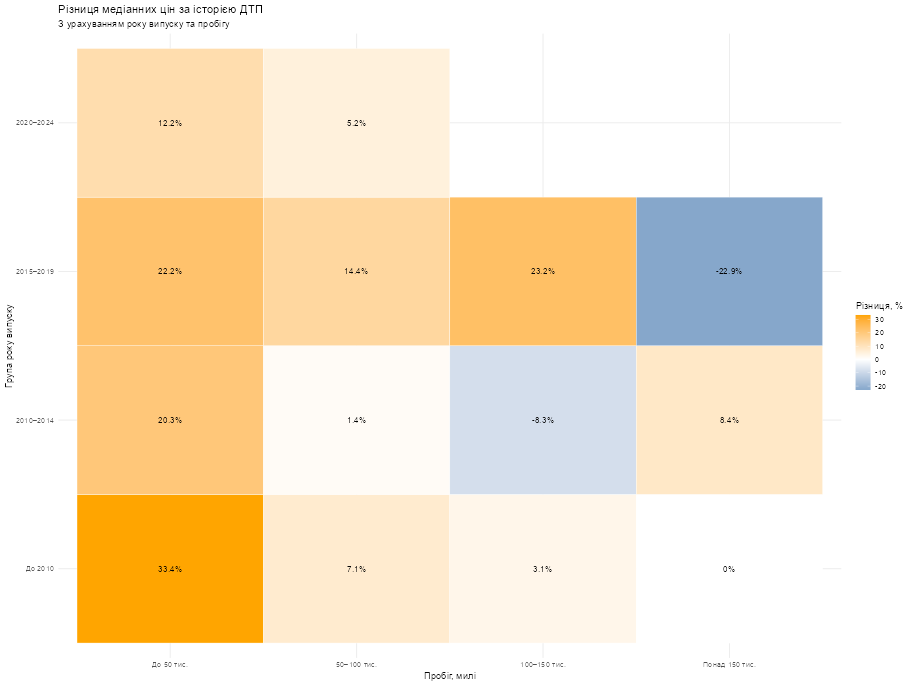

In [55]:

p_multi_heatmap <- ggplot(
  accident_comparison,
  aes(
    x = milage_group,
    y = year_group,
    fill = difference_percent
  )
) +
  geom_tile(color = "white") +
  geom_text(
    aes(
      label = paste0(
        round(difference_percent, 1), "%"
      )
    ),
    size = 3.5
  ) +
  scale_fill_gradient2(
    low = "steelblue",
    mid = "white",
    high = "orange",
    midpoint = 0
  ) +
  labs(
    title = "Різниця медіанних цін за історією ДТП",
    subtitle = "З урахуванням року випуску та пробігу",
    x = "Пробіг, милі",
    y = "Група року випуску",
    fill = "Різниця, %"
  ) +
  theme_minimal()

p_multi_heatmap


#### Це один із найважливіших графіків, оскільки він дозволяє одночасно врахувати чотири змінні: ціну, пробіг, рік випуску та історію ДТП.

### 7.5. Збереження результатів багатовимірного аналізу

#### Збережемо всі необхідні таблиці:

In [56]:

write.csv(
  cor_pearson,
  "../outputs/tables/correlations_pearson.csv"
)

write.csv(
  cor_spearman,
  "../outputs/tables/correlations_spearman.csv"
)

write_csv(
  accident_year_stats,
  "../outputs/tables/accident_year_statistics.csv"
)

write_csv(
  multi_group_stats,
  "../outputs/tables/multivariate_statistics.csv"
)

write_csv(
  accident_comparison,
  "../outputs/tables/accident_comparison.csv"
)


#### Збережемо графіки

In [57]:

ggsave(
  "../outputs/figures/multi_price_milage.png",
  plot = p_multi_milage,
  width = 10, height = 6, dpi = 300
)

ggsave(
  "../outputs/figures/accident_year.png",
  plot = p_accident_year,
  width = 10, height = 6, dpi = 300
)

ggsave(
  "../outputs/figures/multi_heatmap.png",
  plot = p_multi_heatmap,
  width = 10, height = 6, dpi = 300
)


__Оскільки corrplot не є графіком ggplot, його збережемо через png() та dev.off().__

In [58]:

png(
  "../outputs/figures/correlation_pearson.png",
  width = 1800,
  height = 1600,
  res = 200
)

corrplot(
  cor_pearson,
  method = "color",
  type = "upper",
  addCoef.col = "black",
  tl.col = "black",
  tl.srt = 45,
  number.digits = 2,
  title = "Кореляційна матриця Пірсона",
  mar = c(0, 0, 3, 0)
)

dev.off()

png(
  "../outputs/figures/correlation_spearman.png",
  width = 1800,
  height = 1600,
  res = 200
)

corrplot(
  cor_spearman,
  method = "color",
  type = "upper",
  addCoef.col = "black",
  tl.col = "black",
  tl.srt = 45,
  number.digits = 2,
  title = "Кореляційна матриця Спірмена",
  mar = c(0, 0, 3, 0)
)

dev.off()


.ark.graphics.device 
                   2 

### Висновок багатовимірного аналізу

#### Багатовимірний аналіз виявив сильний від'ємний монотонний зв'язок між роком випуску та пробігом автомобілів (кореляція Спірмена близько -0,72).

#### Новіші автомобілі переважно мають менший пробіг та вищу вартість.

#### Порівняння автомобілів за роком випуску та історією ДТП показало, що в усіх чотирьох вікових групах медіанна ціна автомобілів із повідомленнями про ДТП або пошкодження є нижчою на 14–25%.

#### Після додаткового врахування пробігу встановлено, що в 11 із 14 досліджених підгруп автомобілі з повідомленнями про ДТП мають нижчу медіанну ціну.

#### Отримані результати свідчать про необхідність одночасного врахування декількох характеристик під час аналізу вартості автомобілів.

#### Виявлені статистичні зв'язки не є доказом причинно-наслідкових залежностей.

## 8. Підсумкові висновки

### 8.1. Результати підготовки даних

In [59]:

quality_summary <- tibble(
  indicator = c(
    "Кількість спостережень",
    "Кількість змінних",
    "Пропущені значення",
    "Повні дублікати",
    "Некоректні ціни",
    "Некоректний пробіг",
    "Потенційні викиди ціни",
    "Потенційні викиди пробігу"
  ),
  value = c(
    nrow(cars_clean),
    ncol(cars_clean),
    sum(is.na(cars_clean)),
    sum(duplicated(cars_clean)),
    sum(cars_clean$price <= 0),
    sum(cars_clean$milage < 0),
    244,
    69
  )
)

print(quality_summary)

write_csv(
  quality_summary,
  "../outputs/tables/quality_summary.csv"
)


# A tibble: 8 × 2
  indicator                 value
  <chr>                     <dbl>
1 Кількість спостережень     4009
2 Кількість змінних            12
3 Пропущені значення            0
4 Повні дублікати               0
5 Некоректні ціни               0
6 Некоректний пробіг            0
7 Потенційні викиди ціни      244
8 Потенційні викиди пробігу    69


#### __Значення 244 та 69 взяті з фактичних результатів перевірки за правилом IQR на етапі 2.__

## 8.2. Відповіді на дослідницькі запитання

### __1. Як розподіляються ціни вживаних автомобілів?__

#### Розподіл цін має сильну правосторонню асиметрію (коефіцієнт асиметрії — 19,5).

#### Середня ціна автомобіля становить 44 553 USD, а медіанна — 31 000 USD. Центральні 50% автомобілів мають ціни від 17 200 до 49 990 USD.

#### За правилом IQR виявлено 244 потенційні викиди ціни. Наявність автомобілів із надзвичайно високою вартістю суттєво впливає на середнє значення.

#### Для візуалізації розподілу цін доцільно використовувати логарифмічну шкалу, а для характеристики типової вартості — медіану.

### __2. Як рік випуску пов'язаний із ціною автомобіля?__

#### Між роком випуску та ціною автомобіля спостерігається додатний статистичний зв'язок.

#### Кореляція Пірсона: 0,199.

#### Кореляція Спірмена: 0,697.

#### Новіші автомобілі зазвичай мають вищу вартість. Водночас окремі старі автомобілі також можуть мати високу ціну.

#### Коефіцієнт Спірмена показує виражений монотонний зв'язок, який слабше відображається коефіцієнтом лінійної кореляції Пірсона.

### __3. Чи існує зв'язок між пробігом і ціною?__

#### Між пробігом та ціною автомобіля виявлено від'ємний статистичний зв'язок.

### Кореляція Пірсона: −0,306.

### Кореляція Спірмена: −0,755.

#### Зі збільшенням пробігу вартість автомобілів переважно зменшується.

#### Серед досліджених числових характеристик саме пробіг має найсильніший монотонний зв'язок із ціною.

### __4. Як відрізняються ціни залежно від марки та типу пального?__

#### Серед десяти найпоширеніших марок автомобілів найвищі медіанні ціни мають:

#### Porsche — 59 900 USD.

#### Land — 44 924 USD.

#### Mercedes-Benz — 38 598 USD.

#### Найнижчу медіанну ціну серед цих десяти марок має Toyota — 27 999 USD.

#### За типом пального отримано такі медіанні ціни:

### Hybrid — 45 499 USD.

### Diesel — 45 450 USD.

### Plug-In Hybrid — 44 945 USD.

### Unknown — 43 000 USD.

### asoline — 29 950 USD.

### E85 Flex Fuel — 19 500 USD.

#### Отже, ціни автомобілів відрізняються залежно від марки та типу пального. Однак ці відмінності також можуть бути пов'язані з роком випуску, пробігом, комплектацією та іншими характеристиками автомобілів.

### __5. Як пов'язані з ціною історія ДТП, рік випуску та пробіг при спільному аналізі?__

#### Медіанна ціна автомобілів без повідомлень про ДТП становить 35 668 USD, а автомобілів із повідомленнями про ДТП або пошкодження — 20 900 USD.

#### Загальна різниця медіанних цін становить 41,4%.

#### Після врахування року випуску отримано такі відносні різниці медіанних цін:

### До 2010 року — 24,67%.

### 2010–2014 роки — 14,29%.

### 2015–2019 роки — 22,06%.

### 2020–2024 роки — 18,73%.

#### Після додаткового врахування пробігу встановлено, що в 11 із 14 досліджених підгруп автомобілі з повідомленнями про ДТП мають нижчу медіанну ціну. У двох підгрупах спостерігається протилежна ситуація, а в одній різниця становить приблизно 0%.

#### Також виявлено сильний від'ємний монотонний зв'язок між пробігом та роком випуску автомобіля (кореляція Спірмена близько −0,72).

#### Отримані результати показують, що загальну різницю медіанних цін у 41,4% не можна пояснювати виключно історією ДТП. Для коректнішої інтерпретації необхідно одночасно враховувати декілька характеристик автомобілів.

#### Виявлені статистичні зв'язки не доводять причинно-наслідкових залежностей.

### 8.3. Обмеження дослідження

#### - Датасет може не представляти весь ринок вживаних автомобілів.
#### - У деяких категоріальних змінних відсутня інформація, позначена як Unknown.
#### - Наявні екстремальні значення цін та пробігу.
#### - Категорії мають нерівномірну кількість спостережень.
#### - Не враховано всі можливі характеристики автомобілів, зокрема комплектацію та характер пошкоджень.
#### - Групування за роком випуску та пробігом не усуває всіх можливих відмінностей між автомобілями.
#### - Кореляція не доводить причинно-наслідкового зв'язку.
#### - Прогнозна модель у межах цього дослідження не розроблялася.

### 8.4. Загальний висновок лабораторної роботи

#### У межах лабораторної роботи проведено розвідувальний аналіз відкритого датасету вживаних автомобілів, який містить 4009 спостережень та 12 змінних.

#### Виконано перевірку якості даних, очищення, нормалізацію категоріальних значень, описову статистику, одновимірний, двовимірний та багатовимірний аналіз.

#### Встановлено, що серед досліджених числових характеристик найсильніший монотонний зв'язок із ціною мають пробіг та рік випуску. Також виявлено відмінності медіанних цін залежно від марки, типу пального та історії ДТП.

#### Багатовимірний аналіз показав, що одночасне врахування року випуску та пробігу дозволяє точніше інтерпретувати відмінності між групами автомобілів.

#### Усі результати аналізу, таблиці, графіки та очищені дані збережено в окремих каталогах проєкту для забезпечення відтворюваності дослідження.

#### Отримані результати можуть бути використані для подальшого дослідження ринку вживаних автомобілів та розробки моделей прогнозування їхньої вартості.

### 8.5. Збереження метаданих дослідження

In [60]:

dir.create(
  "outputs/metadata",
  recursive = TRUE,
  showWarnings = FALSE
)

metadata <- tibble(
  parameter = c(
    "Dataset",
    "Source",
    "Target variable",
    "Rows",
    "Columns",
    "Missing values strategy",
    "Outlier strategy",
    "Correlation methods",
    "Minimum subgroup size",
    "Language"
  ),
  value = c(
    "Used Car Price Prediction Dataset",
    "https://www.kaggle.com/datasets/taeefnajib/used-car-price-prediction-dataset/data",
    "price",
    as.character(nrow(cars_clean)),
    as.character(ncol(cars_clean)),
    "Unknown for missing categorical values",
    "IQR detection, retain potential outliers",
    "Pearson and Spearman",
    "10 observations per comparison group",
    "R"
  )
)

write_csv(
  metadata,
  "../outputs/metadata/dataset_metadata.csv"
)

writeLines(
  capture.output(sessionInfo()),
  "../outputs/metadata/session_info.txt"
)
